# Closed-loop controller training

The controller runs the frozen LLM, **looks at the result**, then decides to stop, add a run, or escalate.

- **Two controllers:** API and FULL
- **Method:** PPO
- **Models:** 2 controllers × 5 λ × 5 seeds = 50

Finished models are reused, so running this notebook again does not retrain them.

In [1]:
import itertools
import json
import os
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

## 1. Settings

Everything you may want to change is here. `RUN_TEST` stays off until the test run is approved.

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "controller_data").is_dir())
DATA = ROOT / "controller_data"
EMB = DATA / "embeddings"
OUT = Path(os.environ.get("CLOSED_OUT", ROOT / "rl_training" / "outputs" / "closed_loop"))
FIGURES = OUT / "figures" if "CLOSED_OUT" in os.environ else ROOT / "figures" / "closed_loop"
SMOKE = os.environ.get("CLOSED_SMOKE") == "1"
RUN_TEST = os.environ.get("CLOSED_RUN_TEST") == "1"      # evaluate the test split once

PROFILES = ["API", "FULL"]
LAMBDAS = [0.10] if SMOKE else [0.02, 0.05, 0.10, 0.25, 0.50]
SEEDS = [0] if SMOKE else [0, 1, 2, 3, 4]
N_ENVS = 64
TOTAL_STEPS = 12_800 if SMOKE else 1_000_000
EVAL_EVERY = 6_400 if SMOKE else 50_000
EVAL_DRAWS = 20 if SMOKE else 200                        # replay episodes per question
N_BOOT = 200 if SMOKE else 10_000
PPO = dict(lr=3e-4, rollout=2_048, epochs=4, minibatch=256, clip=0.2, gae=0.95, value=0.5,
           ent_start=0.01, ent_end=0.001, grad_clip=0.5, aux=0.1)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CONFIG = "t0.6_pp1.5"
DATASETS = ["gsm8k", "math", "amc23"]
LEVELS = {"gsm8k": [2048, 4096, 16384], "math": [4096, 12288, 16384], "amc23": [12288, 24576, 32768]}
LEVEL_NAMES = ["L", "M", "H"]
ACTIONS = ["RUN_L", "RUN_M", "RUN_H", "STOP", "ADD", "ESC_M", "ESC_H"]
A = {name: i for i, name in enumerate(ACTIONS)}
STOP = A["STOP"]
EMB_DIM = 64
N_SCALARS = {"API": 17, "FULL": 22}
MODELS = [f"{p}-PPO" for p in PROFILES]
BEST_FIXED, RULE, ORACLE = "best fixed plan", "rule: M, escalate if cut", "oracle"

## How seeds work

A **seed** is a starting number for a random-number generator. The same seed gives the same random choices, so a run can be repeated.

| Seed | Value | How it is made | What it controls |
|---|---|---|---|
| Data split | `2026` | fixed in `prepare_data.py` / `prepare_math.py` | which questions go to train, validation, test |
| LLM recording | one per trace | SHA-256 of `question_id\|sample`, first 8 hex digits as a number | the random sampling of that recorded answer |
| **Training** | `0, 1, 2, 3, 4` | written in `SEEDS` | starting weights, sampled questions, traces and actions, minibatch order |
| Scoring | `1234` | fixed in `play()` | the replay draws, the same for every controller |
| Bootstrap | `0` | fixed in `evaluate()` | the question resampling used for the 95% ranges |

Training the same model with 5 seeds shows how much a result depends on luck.

In [3]:
import hashlib

def recording_seed(question_id, sample):
    return int(hashlib.sha256(f"{question_id}|{sample}".encode()).hexdigest()[:8], 16)

print("Recording seeds of question 'gsm8k-1':", [recording_seed("gsm8k-1", k) for k in range(3)])
torch.manual_seed(0); first = torch.rand(3).tolist()
torch.manual_seed(0); again = torch.rand(3).tolist()
torch.manual_seed(1); other = torch.rand(3).tolist()
print("seed 0:", [round(x, 3) for x in first], "| seed 0 again:", [round(x, 3) for x in again], "| seed 1:", [round(x, 3) for x in other])

Recording seeds of question 'gsm8k-1': [1973596014, 3079404675, 3808998835]
seed 0: [0.496, 0.768, 0.088] | seed 0 again: [0.496, 0.768, 0.088] | seed 1: [0.758, 0.279, 0.403]


## 2. Load the recorded answers

Each question becomes a table of **3 levels (L, M, H) × 10 recorded answers**. Equal answers are grouped, such as `7/2` and `3.5`, without using the reference.

In [4]:
sys.path.insert(0, str(ROOT / "generation_math" / "src"))
from grade_math import answer_box, parse, verify  # noqa: E402


def same_answer(a, b):
    try:
        return bool(a and b and (verify(a, b) or verify(b, a)))
    except Exception:
        return False


def cluster_math(preds, boxes):
    """Group equal answers of one question without using the reference. Invalid answers get -1."""
    unique = sorted({p for p in preds if p is not None})
    parent = list(range(len(unique)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    first_box = {}
    for p, b in zip(preds, boxes):
        if p is not None and p not in first_box:
            first_box[p] = b
    parsed = []
    for u in unique:
        try:
            parsed.append(parse("\\boxed{" + first_box[u] + "}"))
        except Exception:
            parsed.append(None)
    for i, j in itertools.combinations(range(len(unique)), 2):
        if find(i) != find(j) and same_answer(parsed[i], parsed[j]):
            parent[find(j)] = find(i)
    roots = {r: n for n, r in enumerate(sorted({find(i) for i in range(len(unique))}))}
    ids = {u: roots[find(i)] for i, u in enumerate(unique)}
    return np.array([ids[p] if p is not None else -1 for p in preds], dtype=np.int16)


def load_set(dataset, split):
    cache = OUT / "cache" / f"{dataset}_{split}.npz"
    q_ids = [str(x) for x in np.load(EMB / f"{dataset}_{split}_q_ids.npy", allow_pickle=True)]
    if cache.exists():
        arrays = dict(np.load(cache))
    else:
        columns = ["question_id", "sample", "budget", "config", "pred", "valid", "correct", "total_tokens", "prompt_tokens",
                   "n_numbers", "finish_reason", "box_confidence", "hedge_per100", "tail_repetition", "loop_by_budget"]
        columns += [] if dataset == "gsm8k" else ["answer_text"]
        df = pd.read_csv(DATA / f"{dataset}_{split}_controller.csv", usecols=columns, na_filter=False,
                         dtype={"question_id": str, "pred": str})
        df = df[(df.config == CONFIG) & df.budget.isin(LEVELS[dataset])]
        assert len(df) == len(q_ids) * 3 * 10, (dataset, split, len(df))
        question = df.question_id.map({q: i for i, q in enumerate(q_ids)}).to_numpy()
        level = df.budget.map({b: i for i, b in enumerate(LEVELS[dataset])}).to_numpy()
        sample = df["sample"].map({s: i for i, s in enumerate(sorted(df["sample"].unique()))}).to_numpy()
        shape = (len(q_ids), 3, 10)
        valid = df.valid.to_numpy().astype(bool)

        def grid(values, kind=np.float32):
            out = np.zeros(shape, kind)
            out[question, level, sample] = np.asarray(values, dtype=kind)
            return out

        arrays = dict(tok=grid(df.total_tokens), cor=grid(df.correct.to_numpy() * valid), cut=grid(df.finish_reason.eq("length")),
                      conf=grid(pd.to_numeric(df.box_confidence)), hedge=grid(pd.to_numeric(df.hedge_per100)),
                      tail=grid(pd.to_numeric(df.tail_repetition)), loop=grid(pd.to_numeric(df.loop_by_budget)))
        preds = np.empty(shape, dtype=object)
        preds[question, level, sample] = [p if v else None for p, v in zip(df.pred, valid)]
        cid = -np.ones(shape, np.int16)
        if dataset == "gsm8k":
            for i in range(len(q_ids)):
                values = [None if p is None else float(p) for p in preds[i].ravel()]
                ids = {v: n for n, v in enumerate(sorted({v for v in values if v is not None}))}
                cid[i] = np.array([-1 if v is None else ids[v] for v in values]).reshape(3, 10)
        else:
            boxes = np.empty(shape, dtype=object)
            boxes[question, level, sample] = [answer_box(t) if v else None for t, v in zip(df.answer_text, valid)]
            for i in range(len(q_ids)):
                cid[i] = cluster_math(list(preds[i].ravel()), list(boxes[i].ravel())).reshape(3, 10)
        first = df.drop_duplicates("question_id").set_index("question_id")
        arrays.update(cid=cid, prompt=pd.to_numeric(first.loc[q_ids, "prompt_tokens"]).to_numpy(np.float32),
                      numbers=pd.to_numeric(first.loc[q_ids, "n_numbers"]).to_numpy(np.float32))
        cache.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(cache, **arrays)
    arrays["emb"] = np.load(EMB / f"{dataset}_{split}_q_{EMB_DIM}.npy").astype(np.float32)
    return arrays

## 3. Fixed plans

A fixed plan does the same thing on every question, for example `M`, or `L → M`. There are **55 legal plans**. Their exact value gives the baseline the controller must beat.

In [5]:
def legal_actions(level, k, runs, t):
    if t == 0:
        return ["RUN_L", "RUN_M", "RUN_H"]
    out = ["STOP"]
    if t < 5 and runs < 6:
        out += ["ADD"] if k < 5 else []
        out += [f"ESC_{LEVEL_NAMES[x]}" for x in (1, 2) if level < x]
    return out


def all_plans():
    found = []

    def walk(actions, stages, level, k, runs, t):
        for name in legal_actions(level, k, runs, t):
            if name == "STOP":
                found.append((tuple(actions + [name]), tuple(stages)))
            elif name == "ADD":
                walk(actions + [name], stages[:-1] + [(level, k + 1)], level, k + 1, runs + 1, t + 1)
            else:
                new_level = LEVEL_NAMES.index(name[-1])
                walk(actions + [name], stages + [(new_level, 1)], new_level, 1, runs + 1, t + 1)

    walk([], [], -1, 0, 0, 0)
    return found


PLANS = all_plans()
COMBOS = {k: np.array(list(itertools.combinations(range(10), k))) for k in range(1, 6)}


def draw_credit(cid, cor, combo):
    """Credit of the majority answer in every draw of traces (ties count equally)."""
    out = np.zeros(len(combo), np.float32)
    n = int(cid.max()) + 1
    if n <= 0:
        return out
    one = np.zeros((10, n), np.float32)
    keep = cid >= 0
    one[np.where(keep)[0], cid[keep]] = 1
    counts = one[combo].sum(1)
    right = (one * cor[:, None])[combo].sum(1)
    top = counts.max(1, keepdims=True)
    tied = (counts == top) & (top > 0)
    share = np.divide(right, counts, out=np.zeros_like(right), where=counts > 0)
    return (tied * share).sum(1) / np.maximum(tied.sum(1), 1)


def fallback(cid, cor, stages, available):
    """Credit from the latest earlier stage when the last stage has no valid answer."""
    if not stages:
        return 0.0
    level, k = stages[-1]
    total, n = 0.0, 0
    for combo in itertools.combinations(available, k):
        valid = [i for i in combo if cid[level, i] >= 0]
        total += float(cor[level, valid].mean()) if valid else fallback(cid, cor, stages[:-1], [i for i in available if i not in combo])
        n += 1
    return total / n


def exact_plan_values(tok, cid, cor):
    n = len(tok)
    acc, tokens = np.zeros((n, len(PLANS)), np.float32), np.zeros((n, len(PLANS)), np.float32)
    base = {(l, k): np.stack([draw_credit(cid[i, l], cor[i, l], COMBOS[k]) for i in range(n)]) for l in range(3) for k in range(1, 6)}
    for s, (_, stages) in enumerate(PLANS):
        level, k = stages[-1]
        acc[:, s] = base[level, k].mean(1)
        tokens[:, s] = sum(kk * tok[:, ll].mean(1) for ll, kk in stages)
        if len(stages) == 1:
            continue
        for i in np.where((cid[np.arange(n), level] < 0).sum(1) >= k)[0]:
            extra = sum(fallback(cid[i], cor[i], list(stages[:-1]), [j for j in range(10) if j not in combo])
                        for combo in COMBOS[k] if (cid[i, level, combo] < 0).all())
            acc[i, s] += extra / len(COMBOS[k])
    return acc, tokens

## 4. Put the data together

Constants such as the cost of one High run (`C_ref`) come from **train only**.

In [6]:
SPLITS = ["train", "val"] + (["test"] if RUN_TEST else [])
S, C_REF, P95, SHARES = {}, {}, {}, None


def load_data():
    global SHARES
    if S:
        return
    (OUT / "cache").mkdir(parents=True, exist_ok=True)
    raw = {(d, s): load_set(d, s) for d in DATASETS for s in SPLITS}
    train = [raw[d, "train"] for d in DATASETS]
    C_REF.update({d: float(raw[d, "train"]["tok"][:, 2].mean()) for d in DATASETS})
    P95.update(prompt=float(np.percentile(np.concatenate([x["prompt"] for x in train]), 95)),
               numbers=float(np.percentile(np.concatenate([x["numbers"] for x in train]), 95)),
               hedge=float(np.percentile(np.concatenate([x["hedge"].ravel() for x in train]), 95)))
    n_train = np.array([len(x["prompt"]) for x in train], float)
    SHARES = np.sqrt(n_train) / np.sqrt(n_train).sum()
    for split in SPLITS:
        parts = [raw[d, split] for d in DATASETS]
        join = lambda key: np.concatenate([p[key] for p in parts])
        ds = np.concatenate([np.full(len(p["tok"]), i) for i, p in enumerate(parts)])
        cache = OUT / "cache" / f"exact_{split}.npz"
        if cache.exists():
            z = np.load(cache)
            acc, tokens = z["acc"], z["tokens"]
        else:
            acc, tokens = exact_plan_values(join("tok"), join("cid"), join("cor"))
            np.savez_compressed(cache, acc=acc, tokens=tokens)
        cref = np.array([C_REF[DATASETS[i]] for i in ds], np.float32)
        budget = np.array([LEVELS[DATASETS[i]] for i in ds], np.float32)
        scalars = np.c_[np.minimum(join("prompt") / P95["prompt"], 1), np.minimum(join("numbers") / P95["numbers"], 1)]
        tensor = lambda v, kind=torch.float32: torch.as_tensor(v, dtype=kind, device=DEVICE)
        S[split] = dict(ds=ds, exact_acc=acc, exact_tokens=tokens, exact_cost=tokens / cref[:, None], emb=tensor(join("emb")),
                        scalars=tensor(scalars), cref=tensor(cref), budget=tensor(budget), tok=tensor(join("tok")),
                        cid=tensor(join("cid").astype(np.int64), torch.long), cor=tensor(join("cor") > 0, torch.bool),
                        cut=tensor(join("cut")), conf=tensor(join("conf")), hedge=tensor(join("hedge")),
                        tail=tensor(join("tail")), loop=tensor(join("loop")))
        S[split]["n_clusters"] = int(S[split]["cid"].max()) + 1


def weighted(values, split):
    return float(sum(SHARES[d] * values[S[split]["ds"] == d].mean() for d in range(3)))

## 5. The replay

1. Pick a dataset (GSM8K 54.9%, MATH 36.2%, AMC 8.9%), then a question.
2. Each run takes one **unused** recorded answer at the chosen level.
3. The controller sees the result and chooses again.
4. **STOP** returns the majority answer.

**Reward** = `1 if the final answer is correct` − `λ × tokens / C_ref`.

| Action | Meaning |
|---|---|
| `RUN_L`, `RUN_M`, `RUN_H` | first run at that level |
| `ADD` | one more run at the same level |
| `ESC_M`, `ESC_H` | one new run at a higher level |
| `STOP` | return the answer |

**API** sees answers, how runs ended, and tokens. **FULL** also sees confidence, hedging, repetition, and loops.

In [7]:
ACTION_LEVEL = torch.tensor([0, 1, 2, -1, -1, 1, 2], device=DEVICE)
LAUNCH = torch.tensor([1, 1, 1, 0, 1, 1, 1], device=DEVICE)
NEW_STAGE = torch.tensor([1, 1, 1, 0, 0, 1, 1], dtype=torch.bool, device=DEVICE)


class Episodes:
    def __init__(self, split, n, profile, lam, gen, questions=None):
        self.x, self.profile, self.lam, self.gen, self.n = S[split], profile, lam, gen, n
        self.clusters = self.x["n_clusters"]
        self.v = self.blank(n)
        self.v["q"] = self.pick_questions(n) if questions is None else questions

    def blank(self, n):
        long = lambda value=0: torch.full((n,), value, dtype=torch.long, device=DEVICE)
        flags = lambda width: torch.zeros(n, width, dtype=torch.bool, device=DEVICE)
        return dict(q=long(), t=long(), level=long(-1), k=long(), runs=long(), win=long(-1), prev_win=long(-1),
                    spent=torch.zeros(n, device=DEVICE), credit=torch.zeros(n, device=DEVICE),
                    prev_credit=torch.zeros(n, device=DEVICE), used=flags(10), current=flags(10),
                    seen=flags(self.clusters), counts=torch.zeros(n, self.clusters, device=DEVICE))

    def rand(self, *shape):
        return torch.rand(*shape, device=DEVICE, generator=self.gen)

    def pick_questions(self, n):
        ds = torch.as_tensor(self.x["ds"], device=DEVICE)
        sizes = torch.bincount(ds, minlength=3)
        offsets = torch.cat([torch.zeros(1, dtype=torch.long, device=DEVICE), sizes.cumsum(0)[:-1]])
        d = torch.multinomial(torch.tensor(SHARES, dtype=torch.float32, device=DEVICE), n, replacement=True, generator=self.gen)
        return offsets[d] + (self.rand(n) * sizes[d]).long()

    def reset(self, where):
        count = int(where.sum())
        if count:
            fresh = self.blank(count)
            fresh["q"] = self.pick_questions(count)
            for key in self.v:
                self.v[key][where] = fresh[key]

    def mask(self):
        v = self.v
        m = torch.zeros(self.n, len(ACTIONS), dtype=torch.bool, device=DEVICE)
        m[v["t"] == 0, :3] = True
        later = v["t"] >= 1
        m[later, STOP] = True
        can_run = later & (v["t"] < 5) & (v["runs"] < 6)
        m[:, A["ADD"]] = can_run & (v["k"] < 5)
        m[:, A["ESC_M"]] = can_run & (v["level"] < 1)
        m[:, A["ESC_H"]] = can_run & (v["level"] < 2)
        return m

    def answer_credit(self):
        return torch.where(self.v["win"] >= 0, self.v["credit"], self.v["prev_credit"])

    def update_answer(self):
        """Majority answer of the current runs. Ties: API at random, FULL by higher confidence."""
        v, x = self.v, self.x
        i = torch.arange(self.n, device=DEVICE)
        q, level = v["q"], v["level"].clamp(min=0)
        cluster = x["cid"][q, level]
        valid = (cluster >= 0) & v["current"]
        slot = cluster.clamp(min=0)
        zeros = lambda: torch.zeros(self.n, self.clusters, device=DEVICE)
        counts = zeros().scatter_add_(1, slot, valid.float())
        right = zeros().scatter_add_(1, slot, (valid & x["cor"][q, level]).float())
        top = counts.max(1, keepdim=True).values
        tied = (counts == top) & (top > 0)
        noise = self.rand(self.n, self.clusters)
        if self.profile == "FULL":
            confidence = zeros().scatter_add_(1, slot, valid.float() * x["conf"][q, level])
            score = tied * (1 + confidence / counts.clamp(min=1) + 1e-6 * noise)
        else:
            score = tied * noise
        winner = score.argmax(1)
        has_answer = top[:, 0] > 0
        v["win"] = torch.where(has_answer, winner, torch.full_like(winner, -1))
        v["credit"] = torch.where(has_answer, right[i, winner] / counts[i, winner].clamp(min=1), torch.zeros_like(top[:, 0]))
        v["counts"] = counts
        v["seen"] = v["seen"] | (counts > 0)

    def step(self, a):
        v, x = self.v, self.x
        stopped = a == STOP
        reward = stopped.float() * self.answer_credit()
        stage = NEW_STAGE[a]
        move = stage & (v["win"] >= 0)                       # escalation: current answer goes to the history
        v["prev_win"] = torch.where(move, v["win"], v["prev_win"])
        v["prev_credit"] = torch.where(move, v["credit"], v["prev_credit"])
        launch = LAUNCH[a]
        v["level"] = torch.where(stage, ACTION_LEVEL[a], v["level"])
        v["k"] = torch.where(stage, launch, v["k"] + launch)
        v["runs"] = v["runs"] + launch
        v["t"] = v["t"] + 1
        order = (self.rand(self.n, 10) - 2.0 * v["used"].float()).argsort(1, descending=True).argsort(1)
        chosen = order < launch[:, None]                     # unused recorded traces only
        v["current"] = (v["current"] & ~stage[:, None]) | chosen
        v["used"] = v["used"] | chosen
        tokens = (x["tok"][v["q"], v["level"].clamp(min=0)] * chosen).sum(1)
        v["spent"] = v["spent"] + tokens
        reward = reward - self.lam * tokens / x["cref"][v["q"]]
        self.update_answer()
        return reward, stopped, tokens

    def mean_over_runs(self, values):
        return (values * self.v["current"].float()).sum(1) / self.v["k"].clamp(min=1).float()

    def state(self):
        """What the controller sees. `correct` is never an input."""
        v, x = self.v, self.x
        q, level = v["q"], v["level"].clamp(min=0)
        K = v["k"].clamp(min=1).float()
        position = [F.one_hot(v["level"] + 1, 4)[:, 1:].float(), v["t"] / 5, v["k"] / 5, v["runs"] / 6,
                    (v["spent"] / x["cref"][q]).clamp(max=3)]
        response = [v["counts"].sum(1) / K, self.mean_over_runs(x["cut"][q, level]),
                    self.mean_over_runs(x["tok"][q, level]) / x["budget"][q, level]]
        share = v["counts"] / K[:, None]
        entropy = -(share * share.clamp(min=1e-9).log()).sum(1)
        entropy = torch.where(K > 1, entropy / K.log().clamp(min=1e-6), torch.zeros_like(K))
        agreement = [v["counts"].max(1).values / K, entropy]
        has_prev = v["prev_win"] >= 0
        history = [has_prev.float(), (has_prev & (v["win"] == v["prev_win"])).float(), v["seen"].sum(1) / v["runs"].clamp(min=1)]
        blocks = position + response + agreement + history
        if self.profile == "FULL":
            conf = x["conf"][q, level]
            lowest = (conf + 9 * (1 - v["current"].float())).min(1).values
            lowest = torch.where(v["k"] > 0, lowest, torch.zeros_like(lowest))
            blocks += [self.mean_over_runs(conf), lowest, (self.mean_over_runs(x["hedge"][q, level]) / P95["hedge"]).clamp(max=1),
                       self.mean_over_runs(x["tail"][q, level]), self.mean_over_runs(x["loop"][q, level])]
        measured = torch.cat([b if b.ndim == 2 else b[:, None] for b in blocks], 1)
        return torch.cat([x["emb"][q], x["scalars"][q], measured], 1)

## 6. The network

`question (64) → 32`, joined with the measurements, then two layers of 64. Outputs: one score per action, the chance the answer is right, and the expected reward. **API has 10,025 parameters, FULL 10,345.**

In [8]:
class ControllerNet(nn.Module):
    def __init__(self, profile):
        super().__init__()
        self.question = nn.Sequential(nn.Linear(EMB_DIM, 32), nn.ReLU())
        self.body = nn.Sequential(nn.Linear(32 + N_SCALARS[profile], 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU())
        self.actions, self.aux, self.value = nn.Linear(64, len(ACTIONS)), nn.Linear(64, 1), nn.Linear(64, 1)

    def forward(self, state):
        h = self.body(torch.cat([self.question(state[:, :EMB_DIM]), state[:, EMB_DIM:]], 1))
        return self.actions(h), self.aux(h).squeeze(1), self.value(h).squeeze(1)


def greedy(model):
    model.eval()
    return lambda env: model(env.state())[0].masked_fill(~env.mask(), -1e9).argmax(1)

## 7. Scoring a controller

Each question is replayed **200 times** with a fixed seed, so every controller is scored on the same random draws.

In [9]:
@torch.no_grad()
def play(policy, split, profile, lam, draws=None, seed=1234, record=False):
    """Accuracy, tokens and utility per question. With record=True, also what the policy did."""
    draws = draws or EVAL_DRAWS
    x = S[split]
    n = len(x["ds"])
    q = torch.arange(n, device=DEVICE).repeat(draws)
    env = Episodes(split, len(q), profile, 0.0, torch.Generator(device=DEVICE).manual_seed(seed), q)
    alive = torch.ones(len(q), dtype=torch.bool, device=DEVICE)
    credit, tokens = torch.zeros(len(q), device=DEVICE), torch.zeros(len(q), device=DEVICE)
    code = torch.zeros(len(q), dtype=torch.long, device=DEVICE)
    first = None
    for t in range(6):
        a = torch.where(alive, policy(env), torch.full_like(q, STOP))
        code[alive] = code[alive] * 10 + a[alive] + 1
        if record and t == 1:
            confidence = env.mean_over_runs(x["conf"][env.v["q"], env.v["level"].clamp(min=0)])
            first = dict(confidence=confidence.cpu().numpy(), stop=(a == STOP).cpu().numpy(), right=env.answer_credit().cpu().numpy())
        reward, stopped, spent = env.step(a)
        credit = torch.where(alive & stopped, reward, credit)
        tokens += spent
        alive = alive & ~stopped
    acc = credit.view(draws, n).mean(0).cpu().numpy()
    tok = tokens.view(draws, n).mean(0).cpu().numpy()
    out = dict(acc=acc, tokens=tok, utility=acc - lam * tok / x["cref"].cpu().numpy())
    if record:
        out.update(code=code.cpu().numpy(), ds=x["ds"][q.cpu().numpy()], first=first)
    return out

## 8. PPO training

1. Play a batch of episodes.
2. Measure which actions did better than expected.
3. Make those actions more likely.
4. Every 50,000 steps, keep the version with the best validation utility.

In [10]:
def train_ppo(profile, lam, seed):
    torch.manual_seed(seed)
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    env = Episodes("train", N_ENVS, profile, lam, gen)
    model = ControllerNet(profile).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=PPO["lr"])
    horizon, width = PPO["rollout"] // N_ENVS, EMB_DIM + N_SCALARS[profile]
    steps, next_eval, best, best_state, curve = 0, EVAL_EVERY, -np.inf, None, []

    while steps < TOTAL_STEPS:
        progress = steps / TOTAL_STEPS
        for group in opt.param_groups:
            group["lr"] = PPO["lr"] * (1 - progress)
        entropy_weight = PPO["ent_start"] + (PPO["ent_end"] - PPO["ent_start"]) * progress

        # Play a batch of episodes.
        s_b = torch.zeros(horizon, N_ENVS, width, device=DEVICE)
        m_b = torch.zeros(horizon, N_ENVS, len(ACTIONS), dtype=torch.bool, device=DEVICE)
        a_b = torch.zeros(horizon, N_ENVS, dtype=torch.long, device=DEVICE)
        logp_b, v_b, r_b, d_b, aux_b = [torch.zeros(horizon, N_ENVS, device=DEVICE) for _ in range(5)]
        on_b = torch.zeros(horizon, N_ENVS, dtype=torch.bool, device=DEVICE)
        model.eval()
        for h in range(horizon):
            s, mask = env.state(), env.mask()
            aux_b[h], on_b[h] = env.answer_credit(), env.v["t"] >= 1
            with torch.no_grad():
                logits, _, value = model(s)
                dist = torch.distributions.Categorical(logits=logits.masked_fill(~mask, -1e9))
                a = dist.sample()
            r, done, _ = env.step(a)
            s_b[h], m_b[h], a_b[h], logp_b[h], v_b[h], r_b[h], d_b[h] = s, mask, a, dist.log_prob(a), value, r, done.float()
            env.reset(done)

        # How much better than expected was each action?
        with torch.no_grad():
            last = model(env.state())[2]
        advantage, running = torch.zeros_like(r_b), torch.zeros(N_ENVS, device=DEVICE)
        for h in reversed(range(horizon)):
            next_value = last if h == horizon - 1 else v_b[h + 1]
            delta = r_b[h] + (1 - d_b[h]) * next_value - v_b[h]
            running = delta + PPO["gae"] * (1 - d_b[h]) * running
            advantage[h] = running
        returns = advantage + v_b
        s_f, m_f, a_f, logp_f, ret_f, adv_f, aux_f, on_f = [
            b.reshape(horizon * N_ENVS, *b.shape[2:]) for b in (s_b, m_b, a_b, logp_b, returns, advantage, aux_b, on_b)]

        # Make better-than-expected actions more likely.
        model.train()
        for _ in range(PPO["epochs"]):
            order = torch.randperm(len(s_f), device=DEVICE)
            for start in range(0, len(order), PPO["minibatch"]):
                j = order[start:start + PPO["minibatch"]]
                logits, aux, value = model(s_f[j])
                dist = torch.distributions.Categorical(logits=logits.masked_fill(~m_f[j], -1e9))
                ratio = (dist.log_prob(a_f[j]) - logp_f[j]).exp()
                norm = (adv_f[j] - adv_f[j].mean()) / (adv_f[j].std() + 1e-8)
                policy_loss = -torch.min(ratio * norm, ratio.clamp(1 - PPO["clip"], 1 + PPO["clip"]) * norm).mean()
                loss = policy_loss + PPO["value"] * F.mse_loss(value, ret_f[j]) - entropy_weight * dist.entropy().mean()
                if on_f[j].any():
                    loss = loss + PPO["aux"] * F.binary_cross_entropy_with_logits(aux[on_f[j]], aux_f[j][on_f[j]])
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), PPO["grad_clip"])
                opt.step()
        steps += horizon * N_ENVS

        # Keep the version with the best validation utility.
        if steps >= next_eval:
            score = weighted(play(greedy(model), "val", profile, lam)["utility"], "val")
            curve.append(dict(model=f"{profile}-PPO", lam=lam, seed=seed, steps=steps, val_utility=score))
            if score > best:
                best, best_state = score, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            next_eval += EVAL_EVERY
    return best_state, curve


def model_path(name, lam, seed):
    return OUT / f"{name}_lam{lam}_seed{seed}.pt"


def train_all():
    load_data()
    for profile, size in (("API", 10_025), ("FULL", 10_345)):
        assert sum(p.numel() for p in ControllerNet(profile).parameters()) == size
    started, curves = time.time(), []
    for profile in PROFILES:
        name = f"{profile}-PPO"
        for lam in LAMBDAS:
            for seed in SEEDS:
                path, curve_path = model_path(name, lam, seed), OUT / f"{name}_lam{lam}_seed{seed}_curve.json"
                if path.exists() and curve_path.exists() and not SMOKE:
                    curves += json.loads(curve_path.read_text())
                    continue
                t0 = time.time()
                state, curve = train_ppo(profile, lam, seed)
                torch.save(state, path)
                curve_path.write_text(json.dumps(curve))
                curves += curve
                print(f"{name} λ={lam} seed {seed}: best val utility {max(c['val_utility'] for c in curve):.4f} "
                      f"({time.time() - t0:.0f}s)", flush=True)
    pd.DataFrame(curves).to_csv(OUT / "learning_curves.csv", index=False)
    print(f"training done in {(time.time() - started) / 60:.1f} min", flush=True)

## 9. Result calculations

Each λ reports its **median seed**. A difference is called clear only if it survives the bootstrap and Holm test.

In [11]:
def plan_name(code):
    short = {"RUN_L": "L", "RUN_M": "M", "RUN_H": "H", "ADD": "+", "ESC_M": "→M", "ESC_H": "→H"}
    return " ".join(short[ACTIONS[int(d) - 1]] for d in str(code) if ACTIONS[int(d) - 1] != "STOP")


def load_model(name, lam, seed):
    model = ControllerNet(name.split("-")[0]).to(DEVICE)
    model.load_state_dict(torch.load(model_path(name, lam, seed), map_location=DEVICE))
    return model.eval()


def median_seed(name, lam):
    profile = name.split("-")[0]
    scores = sorted((weighted(play(greedy(load_model(name, lam, s)), "val", profile, lam)["utility"], "val"), s) for s in SEEDS)
    return scores[len(scores) // 2][1]


def exact_result(split, lam, plan):
    x, i = S[split], np.arange(len(S[split]["ds"]))
    return dict(acc=x["exact_acc"][i, plan], tokens=x["exact_tokens"][i, plan], utility=x["exact_acc"][i, plan] - lam * x["exact_cost"][i, plan])


def best_fixed(split, lam):
    tr = S["train"]
    best = [int((tr["exact_acc"][tr["ds"] == d] - lam * tr["exact_cost"][tr["ds"] == d]).mean(0).argmax()) for d in range(3)]
    return exact_result(split, lam, np.array(best)[S[split]["ds"]])


def oracle(split, lam):
    x = S[split]
    return exact_result(split, lam, (x["exact_acc"] - lam * x["exact_cost"]).argmax(1))


def rule_cut(env):
    """One Medium run. Escalate to High if it was cut by the budget, otherwise stop."""
    t = env.v["t"]
    was_cut = (env.x["cut"][env.v["q"], env.v["level"].clamp(min=0)] * env.v["current"]).sum(1) > 0
    second = torch.where(was_cut, torch.full_like(t, A["ESC_H"]), torch.full_like(t, STOP))
    return torch.where(t == 0, torch.full_like(t, A["RUN_M"]), torch.where(t == 1, second, torch.full_like(t, STOP)))


def holm(p_values):
    p = np.asarray(p_values)
    out, running = np.zeros(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        out[i] = running
    return out


def compare(label, pairs, chosen, split, rng):
    family = []
    for model, reference, lam in pairs:
        diff = chosen[model, lam]["utility"] - chosen[reference, lam]["utility"]
        parts = [diff[S[split]["ds"] == d][rng.integers((S[split]["ds"] == d).sum(), size=(N_BOOT, (S[split]["ds"] == d).sum()))].mean(1)
                 for d in range(3)]
        boots = (SHARES[:, None] * np.stack(parts)).sum(0)
        p = min(1.0, 2 * min((1 + (boots <= 0).sum()) / (N_BOOT + 1), (1 + (boots >= 0).sum()) / (N_BOOT + 1)))
        family.append(dict(comparison=label, model=model, reference=reference, lam=lam, gain=weighted(diff, split),
                           ci_low=np.percentile(boots, 2.5), ci_high=np.percentile(boots, 97.5), p=p))
    for row, adjusted in zip(family, holm([r["p"] for r in family])):
        row["p_holm"] = adjusted
        row["verdict"] = "no clear difference" if adjusted >= 0.05 else ("clear gain" if row["gain"] > 0 else "clear loss")
    return family


def evaluate():
    load_data()
    split = "test" if RUN_TEST else "val"
    marker = OUT / "test_done.json"
    if RUN_TEST and marker.exists():
        raise RuntimeError("The test split was already evaluated.")
    rows, chosen, sequences, decisions = [], {}, [], []

    def add(name, lam, result):
        chosen[name, lam] = result
        for d, dataset in enumerate(DATASETS):
            m = S[split]["ds"] == d
            rows.append(dict(model=name, lam=lam, dataset=dataset, accuracy=result["acc"][m].mean(),
                             tokens=result["tokens"][m].mean(), cost=result["tokens"][m].mean() / C_REF[dataset],
                             utility=result["utility"][m].mean()))
        rows.append(dict(model=name, lam=lam, dataset="all (weighted)", accuracy=weighted(result["acc"], split), tokens=np.nan,
                         cost=sum(SHARES[d] * result["tokens"][S[split]["ds"] == d].mean() / C_REF[DATASETS[d]] for d in range(3)),
                         utility=weighted(result["utility"], split)))

    bins = [0, .5, .7, .85, .95, 1.01]
    labels = ["<0.50", "0.50–0.70", "0.70–0.85", "0.85–0.95", "≥0.95"]
    for lam in LAMBDAS:
        for name in MODELS:
            profile = name.split("-")[0]
            result = play(greedy(load_model(name, lam, median_seed(name, lam))), split, profile, lam, record=True)
            add(name, lam, result)
            for d, dataset in enumerate(DATASETS + ["all (weighted)"]):
                codes = result["code"] if d == 3 else result["code"][result["ds"] == d]
                for code, count in Counter(codes.tolist()).items():
                    sequences.append(dict(model=name, lam=lam, dataset=dataset, plan=plan_name(code), share=count / len(codes)))
            f = result["first"]
            for low, high, label in zip(bins, bins[1:], labels):
                m = (f["confidence"] >= low) & (f["confidence"] < high)
                if m.any():
                    decisions.append(dict(model=name, lam=lam, confidence=label, share_of_answers=m.mean(),
                                          answer_correct=f["right"][m].mean(), controller_stops=f["stop"][m].mean()))
        add(BEST_FIXED, lam, best_fixed(split, lam))
        add(RULE, lam, play(rule_cut, split, "API", lam))
        add(ORACLE, lam, oracle(split, lam))

    pd.DataFrame(rows).to_csv(OUT / f"{split}_metrics.csv", index=False)
    pd.DataFrame(sequences).to_csv(OUT / f"{split}_policies.csv", index=False)
    pd.DataFrame(decisions).to_csv(OUT / f"{split}_confidence.csv", index=False)
    rng = np.random.default_rng(0)
    gains = compare("vs best fixed plan", [(m, BEST_FIXED, l) for m in MODELS for l in LAMBDAS], chosen, split, rng) \
        + compare("FULL vs API", [("FULL-PPO", "API-PPO", l) for l in LAMBDAS], chosen, split, rng)
    pd.DataFrame(gains).to_csv(OUT / f"{split}_comparisons.csv", index=False)
    if RUN_TEST:
        marker.write_text(json.dumps(dict(seeds=SEEDS, time=time.strftime("%Y-%m-%d %H:%M:%S"))))
    draw_figures(split)
    print("results saved to", OUT, "| figures in", FIGURES, flush=True)

## 10. Figure style

All figures use the same colors, fonts, and layout.

In [12]:
INK, MUTED, GRID, SURFACE = "#2b2b29", "#6f6e68", "#e6e5df", "#fcfcfb"
COLORS = {"API-PPO": "#2a78d6", "FULL-PPO": "#eb6834", BEST_FIXED: "#1baf7a"}
MARKERS = {"API-PPO": "o", "FULL-PPO": "^", BEST_FIXED: "s"}
NICE = {"API-PPO": "API controller", "FULL-PPO": "FULL controller", BEST_FIXED: "Best fixed plan"}
TITLES = {"gsm8k": "GSM8K", "math": "MATH", "amc23": "AMC 2023"}


def style():
    plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                         "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.grid": True,
                         "grid.color": GRID, "grid.linewidth": .7, "axes.spines.top": False, "axes.spines.right": False,
                         "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "left", "legend.frameon": False})


def finish(fig, name, title):
    fig.suptitle(title, x=.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout()
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{name}.png", dpi=160)
    plt.show()


def draw_figures(split):
    style()
    word = "Test" if split == "test" else "Validation"
    metrics = pd.read_csv(OUT / f"{split}_metrics.csv")
    gains = pd.read_csv(OUT / f"{split}_comparisons.csv")
    policies = pd.read_csv(OUT / f"{split}_policies.csv")
    confidence = pd.read_csv(OUT / f"{split}_confidence.csv")

    # 1. Accuracy against cost
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, d in zip(axes, DATASETS):
        part = metrics[metrics.dataset == d]
        for model in [BEST_FIXED, "API-PPO", "FULL-PPO"]:
            line = part[part.model == model].sort_values("cost")
            ax.plot(line.cost, 100 * line.accuracy, color=COLORS[model], marker=MARKERS[model], lw=2, ms=7, mec=SURFACE, mew=1.5, label=NICE[model])
        ax.set_title(TITLES[d])
        ax.set_xlabel("tokens per question (1 = one High run)")
    axes[0].set_ylabel("accuracy (%)")
    axes[-1].legend(loc="lower right")
    finish(fig, f"{split}_01_accuracy_vs_cost", f"Accuracy against token cost ({word})")

    # 2. Gain over the best fixed plan
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    table = gains[gains.comparison == "vs best fixed plan"]
    for model, shift in (("API-PPO", -.07), ("FULL-PPO", .07)):
        line = table[table.model == model].sort_values("lam")
        x = np.arange(len(line)) + shift
        ax.errorbar(x, line.gain, yerr=[line.gain - line.ci_low, line.ci_high - line.gain], color=COLORS[model], marker=MARKERS[model],
                    lw=2, ms=7, mec=SURFACE, mew=1.5, capsize=3, label=NICE[model])
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(range(len(LAMBDAS)), LAMBDAS)
    ax.set_xlabel("λ (how expensive tokens are)")
    ax.set_ylabel("utility gain over best fixed plan")
    ax.legend(loc="upper right")
    finish(fig, f"{split}_02_gain", f"Gain over the best fixed plan, with 95% range ({word})")

    # 3. Plans each controller chose
    part = policies[policies.dataset == "all (weighted)"]
    top = part.groupby("plan").share.max().sort_values(ascending=False).head(10).index.tolist()
    index = [(m, l) for m in MODELS for l in LAMBDAS]
    grid = np.array([[part[(part.model == m) & (part.lam == l) & (part.plan == p)].share.sum() for p in top] for m, l in index])
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    ax.grid(False)
    image = ax.imshow(grid, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(top)), top, rotation=30, ha="right")
    ax.set_yticks(range(len(index)), [f"{m.split('-')[0]}, λ = {l}" for m, l in index])
    ax.set_xlabel("plan (L, M, H = one run; + = add a run; → = escalate)")
    for r, c in zip(*np.where(grid >= .05)):
        ax.text(c, r, f"{grid[r, c]:.0%}", ha="center", va="center", fontsize=8, color="white" if grid[r, c] > .55 else INK)
    fig.colorbar(image, ax=ax, label="share of episodes")
    finish(fig, f"{split}_03_policies", f"Plans chosen by each controller ({word})")

    # 4. How confidence drives the FULL controller
    order = ["<0.50", "0.50–0.70", "0.70–0.85", "0.85–0.95", "≥0.95"]
    show = [l for l in LAMBDAS if l in (0.02, 0.10, 0.25)] or LAMBDAS
    fig, axes = plt.subplots(1, len(show), figsize=(4.3 * len(show), 3.9), sharey=True, squeeze=False)
    for ax, lam in zip(axes[0], show):
        line = confidence[(confidence.model == "FULL-PPO") & (confidence.lam == lam)].set_index("confidence").reindex(order)
        ax.plot(order, 100 * line.answer_correct, color=COLORS[BEST_FIXED], marker="s", lw=2, ms=7, mec=SURFACE, mew=1.5, label="answer is correct")
        ax.plot(order, 100 * line.controller_stops, color=COLORS["FULL-PPO"], marker="^", lw=2, ms=7, mec=SURFACE, mew=1.5, label="controller stops")
        ax.set_title(f"λ = {lam}")
        ax.set_xlabel("answer confidence after the first run")
        ax.tick_params(axis="x", labelsize=8)
    axes[0][0].set_ylabel("share (%)")
    axes[0][-1].legend(loc="lower right")
    finish(fig, f"{split}_04_confidence", f"FULL controller: confidence and the decision to stop ({word})")

    # 5. Learning curves
    curves = pd.read_csv(OUT / "learning_curves.csv")
    fig, axes = plt.subplots(1, len(LAMBDAS), figsize=(3.1 * len(LAMBDAS), 3.3), squeeze=False)
    for ax, lam in zip(axes[0], LAMBDAS):
        for model in MODELS:
            mean = curves[(curves.model == model) & (curves.lam == lam)].groupby("steps").val_utility.mean()
            ax.plot(mean.index / 1e6, mean.values, color=COLORS[model], lw=2, label=NICE[model])
        ax.set_title(f"λ = {lam}")
        ax.set_xlabel("million steps")
    axes[0][0].set_ylabel("validation utility")
    axes[0][-1].legend(loc="lower right", fontsize=8)
    finish(fig, "05_learning_curves", "Learning curves (mean of 5 seeds)")

## 11. Train and evaluate

Models already saved are skipped.

training done in 0.0 min


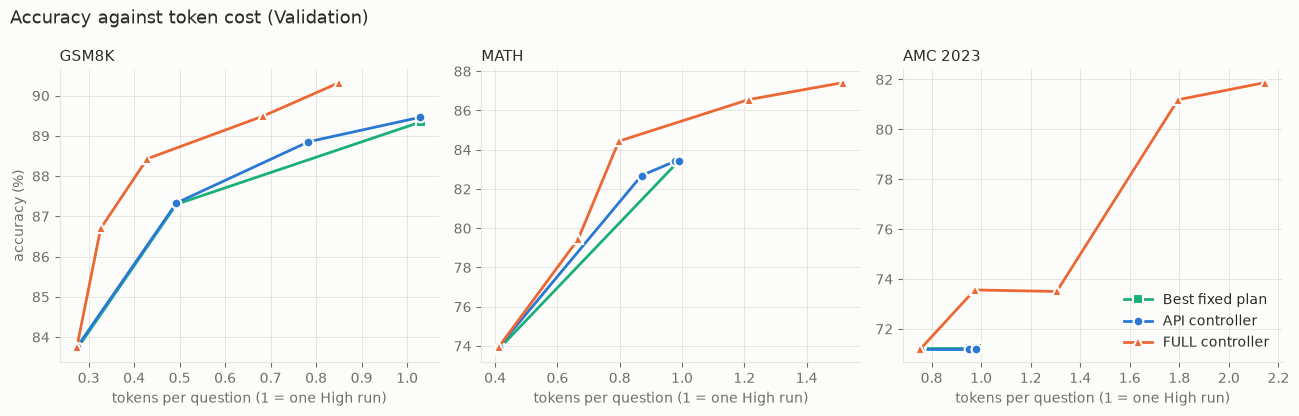

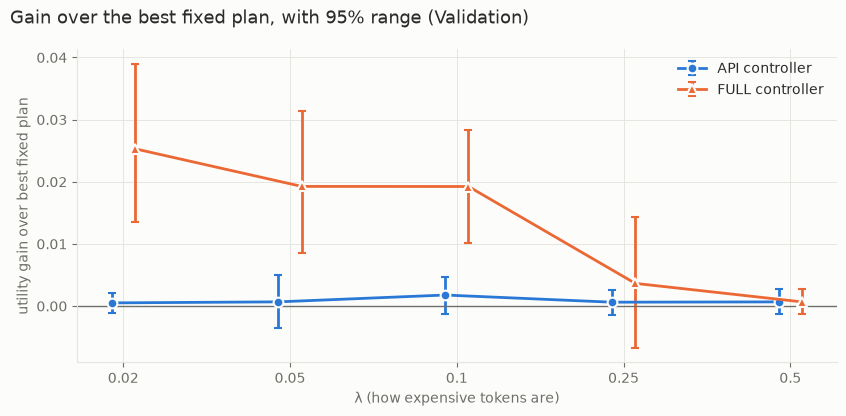

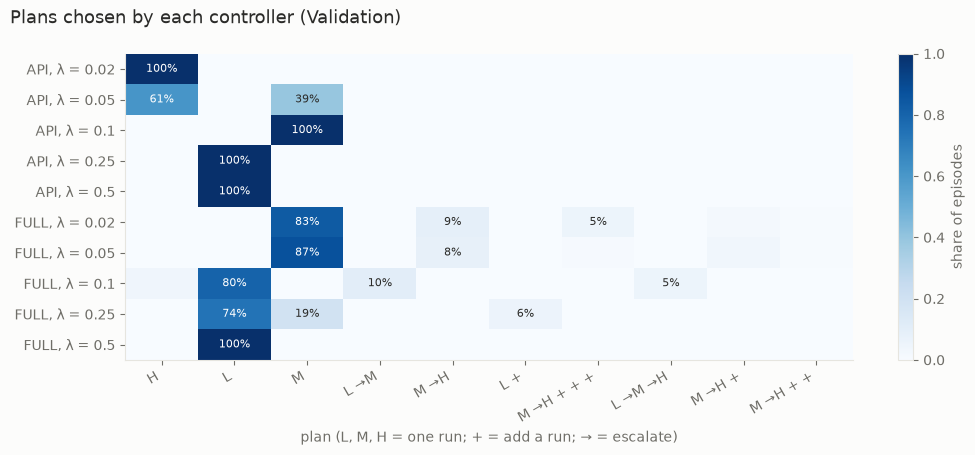

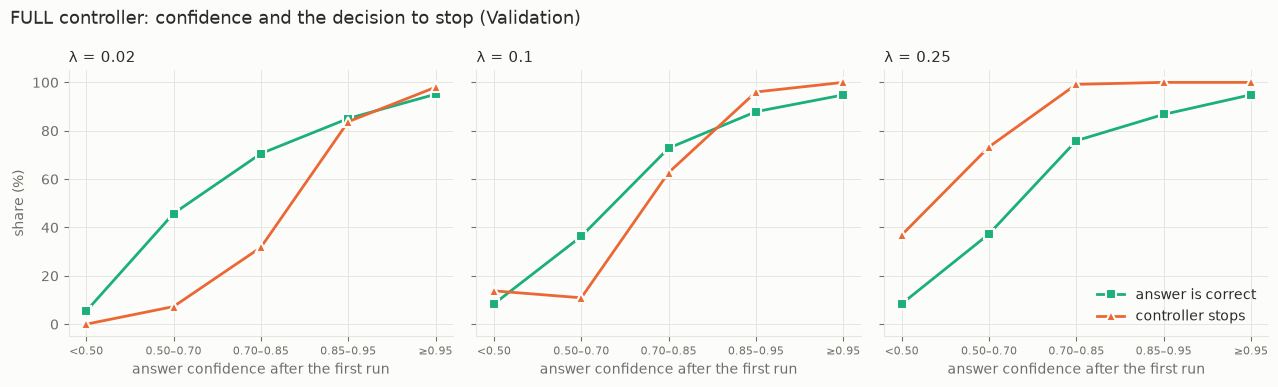

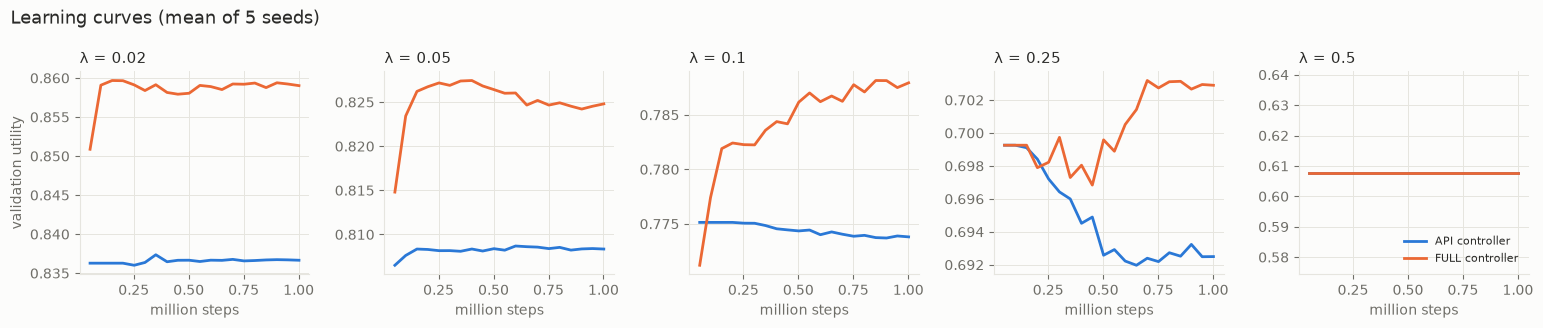

results saved to /home/michel/Desktop/RL_experiments/rl_training/outputs/closed_loop | figures in /home/michel/Desktop/RL_experiments/figures/closed_loop


In [13]:
train_all()
evaluate()

## 12. Results

Higher utility is better.

In [14]:
from IPython.display import Image, display
split = "test" if RUN_TEST else "val"
metrics = pd.read_csv(OUT / f"{split}_metrics.csv")
order = MODELS + [BEST_FIXED, RULE, ORACLE]
for value in ("utility", "accuracy"):
    print(f"\n{value}, all datasets")
    display(metrics[metrics.dataset == "all (weighted)"].pivot(index="lam", columns="model", values=value)[order].round(4))
for dataset in DATASETS:
    print(f"\n{dataset}: accuracy and tokens")
    part = metrics[(metrics.dataset == dataset) & metrics.model.isin(MODELS + [BEST_FIXED])]
    display(part.pivot(index="lam", columns="model", values=["accuracy", "tokens"]).round(3))


utility, all datasets


model,API-PPO,FULL-PPO,best fixed plan,"rule: M, escalate if cut",oracle
lam,,,,,
0.02,0.8363,0.8611,0.8358,0.8221,0.8714
0.05,0.8096,0.8282,0.8089,0.7826,0.8435
0.10,0.7751,0.7926,0.7734,0.7167,0.8085
0.25,0.6993,0.7023,0.6986,0.5192,0.7278
0.50,0.6077,0.6077,0.6070,0.1899,0.6194



accuracy, all datasets


model,API-PPO,FULL-PPO,best fixed plan,"rule: M, escalate if cut",oracle
lam,,,,,
0.02,0.8565,0.8852,0.8560,0.8484,0.8929
0.05,0.8531,0.8769,0.8448,0.8484,0.8855
0.10,0.8422,0.8566,0.8448,0.8484,0.8705
0.25,0.7908,0.8290,0.7902,0.8484,0.8476
0.50,0.7908,0.7908,0.7902,0.8484,0.8219



gsm8k: accuracy and tokens


accuracy                             tokens                          
model  API-PPO FULL-PPO best fixed plan   API-PPO  FULL-PPO best fixed plan
lam                                                                        
0.02     0.895    0.903           0.894  7074.002  5846.096        7087.595
0.05     0.889    0.895           0.873  5381.605  4699.518        3387.139
0.10     0.873    0.884           0.873  3387.952  2945.744        3387.139
0.25     0.837    0.867           0.837  1882.894  2242.837        1883.015
0.50     0.837    0.837           0.837  1882.894  1882.894        1883.015


math: accuracy and tokens


accuracy                             tokens                           
model  API-PPO FULL-PPO best fixed plan   API-PPO   FULL-PPO best fixed plan
lam                                                                         
0.02     0.834    0.874           0.834  8645.104  13259.835        8653.161
0.05     0.834    0.866           0.834  8538.906  10616.294        8653.161
0.10     0.827    0.844           0.834  7602.935   6966.385        8653.161
0.25     0.739    0.794           0.738  3590.963   5824.813        3592.343
0.50     0.739    0.739           0.738  3590.963   3590.963        3592.343


amc23: accuracy and tokens


accuracy                              tokens                           
model  API-PPO FULL-PPO best fixed plan    API-PPO   FULL-PPO best fixed plan
lam                                                                          
0.02     0.712    0.819           0.712  12707.395  27891.471       12797.725
0.05     0.712    0.812           0.712  12707.395  23338.725       12797.725
0.10     0.712    0.735           0.712  12372.682  16971.096       12420.611
0.25     0.712    0.736           0.712   9807.058  12665.047        9827.188
0.50     0.712    0.712           0.712   9807.058   9807.058        9827.188

## 13. Comparisons

In [15]:
display(pd.read_csv(OUT / f"{split}_comparisons.csv").round(4))

,comparison,model,reference,lam,gain,ci_low,ci_high,p,p_holm,verdict
0,vs best fixed plan,API-PPO,best fixed plan,0.02,0.0005,-0.0012,0.0022,0.5497,1.0000,no clear difference
1,vs best fixed plan,API-PPO,best fixed plan,0.05,0.0007,-0.0035,0.0051,0.7835,1.0000,no clear difference
2,vs best fixed plan,API-PPO,best fixed plan,0.10,0.0018,-0.0013,0.0047,0.2516,1.0000,no clear difference
3,vs best fixed plan,API-PPO,best fixed plan,0.25,0.0006,-0.0014,0.0026,0.5515,1.0000,no clear difference
4,vs best fixed plan,API-PPO,best fixed plan,0.50,0.0007,-0.0013,0.0027,0.5003,1.0000,no clear difference
5,vs best fixed plan,FULL-PPO,best fixed plan,0.02,0.0253,0.0135,0.0390,0.0002,0.0020,clear gain
6,vs best fixed plan,FULL-PPO,best fixed plan,0.05,0.0193,0.0086,0.0314,0.0006,0.0048,clear gain
7,vs best fixed plan,FULL-PPO,best fixed plan,0.10,0.0192,0.0101,0.0283,0.0002,0.0020,clear gain
8,vs best fixed plan,FULL-PPO,best fixed plan,0.25,0.0037,-0.0068,0.0143,0.4974,1.0000,no clear difference
9,vs best fixed plan,FULL-PPO,best fixed plan,0.50,0.0007,-0.0013,0.0027,0.4830,1.0000,no clear difference


## 14. Which policy did each controller choose?

`L`, `M`, `H` = one run. `+` = add a run. `→` = escalate.

In [16]:
policies = pd.read_csv(OUT / f"{split}_policies.csv")
top = (policies.sort_values("share", ascending=False).groupby(["model", "lam", "dataset"]).head(3)
       .assign(text=lambda x: x.plan + " " + (100 * x.share).round().astype(int).astype(str) + "%")
       .groupby(["model", "lam", "dataset"]).text.agg(", ".join).unstack())
display(top[DATASETS + ["all (weighted)"]])
print("How confidence drives the first decision (FULL)")
confidence = pd.read_csv(OUT / f"{split}_confidence.csv")
display(confidence[confidence.model == "FULL-PPO"].round(3))

dataset                              gsm8k                            math  \
model    lam                                                                 
API-PPO  0.02                       H 100%                          H 100%   
         0.05                 M 50%, H 50%                    H 81%, M 19%   
         0.10                       M 100%                          M 100%   
         0.25                       L 100%                          L 100%   
         0.50                       L 100%                          L 100%   
FULL-PPO 0.02   M 85%, M →H 10%, M →H + 2%  M 80%, M →H + + + 10%, M →H 7%   
         0.05    M 90%, M →H 8%, M →H + 2%       M 85%, M →H 7%, M →H + 5%   
         0.10  L 85%, L →M 11%, L →M →H 4%           L 74%, L →M 10%, H 9%   
         0.25         L 82%, M 11%, L + 6%            L 59%, M 35%, L + 5%   
         0.50                       L 100%                          L 100%   

dataset                                  amc23                 all (weighted)  
model    lam                                                                   
API-PPO  0.02                           H 100%                         H 100%  
         0.05                     H 88%, M 12%                   H 61%, M 39%  
         0.10                           M 100%                         M 100%  
         0.25                           L 100%                         L 100%  
         0.50                           L 100%                         L 100%  
FULL-PPO 0.02  M 62%, M →H + + + 26%, M →H 10%  M 83%, M →H 9%, M →H + + + 5%  
         0.05      M 62%, M →H + 14%, M →H 10%      M 87%, M →H 8%, M →H + 3%  
         0.10        L 50%, H 25%, L →M →H 21%    L 80%, L →M 10%, L →M →H 5%  
         0.25             L 54%, M 38%, L + 8%           L 74%, M 19%, L + 6%  
         0.50                           L 100%                         L 100%

How confidence drives the first decision (FULL)


,model,lam,confidence,share_of_answers,answer_correct,controller_stops
5,FULL-PPO,0.02,<0.50,0.053,0.054,0.000
6,FULL-PPO,0.02,0.50–0.70,0.037,0.458,0.073
7,FULL-PPO,0.02,0.70–0.85,0.057,0.705,0.318
8,FULL-PPO,0.02,0.85–0.95,0.169,0.851,0.837
9,FULL-PPO,0.02,≥0.95,0.684,0.951,0.980
15,FULL-PPO,0.05,<0.50,0.053,0.054,0.000
16,FULL-PPO,0.05,0.50–0.70,0.037,0.458,0.098
17,FULL-PPO,0.05,0.70–0.85,0.057,0.705,0.478
18,FULL-PPO,0.05,0.85–0.95,0.169,0.851,0.958
19,FULL-PPO,0.05,≥0.95,0.684,0.951,0.997


## 15. Figures

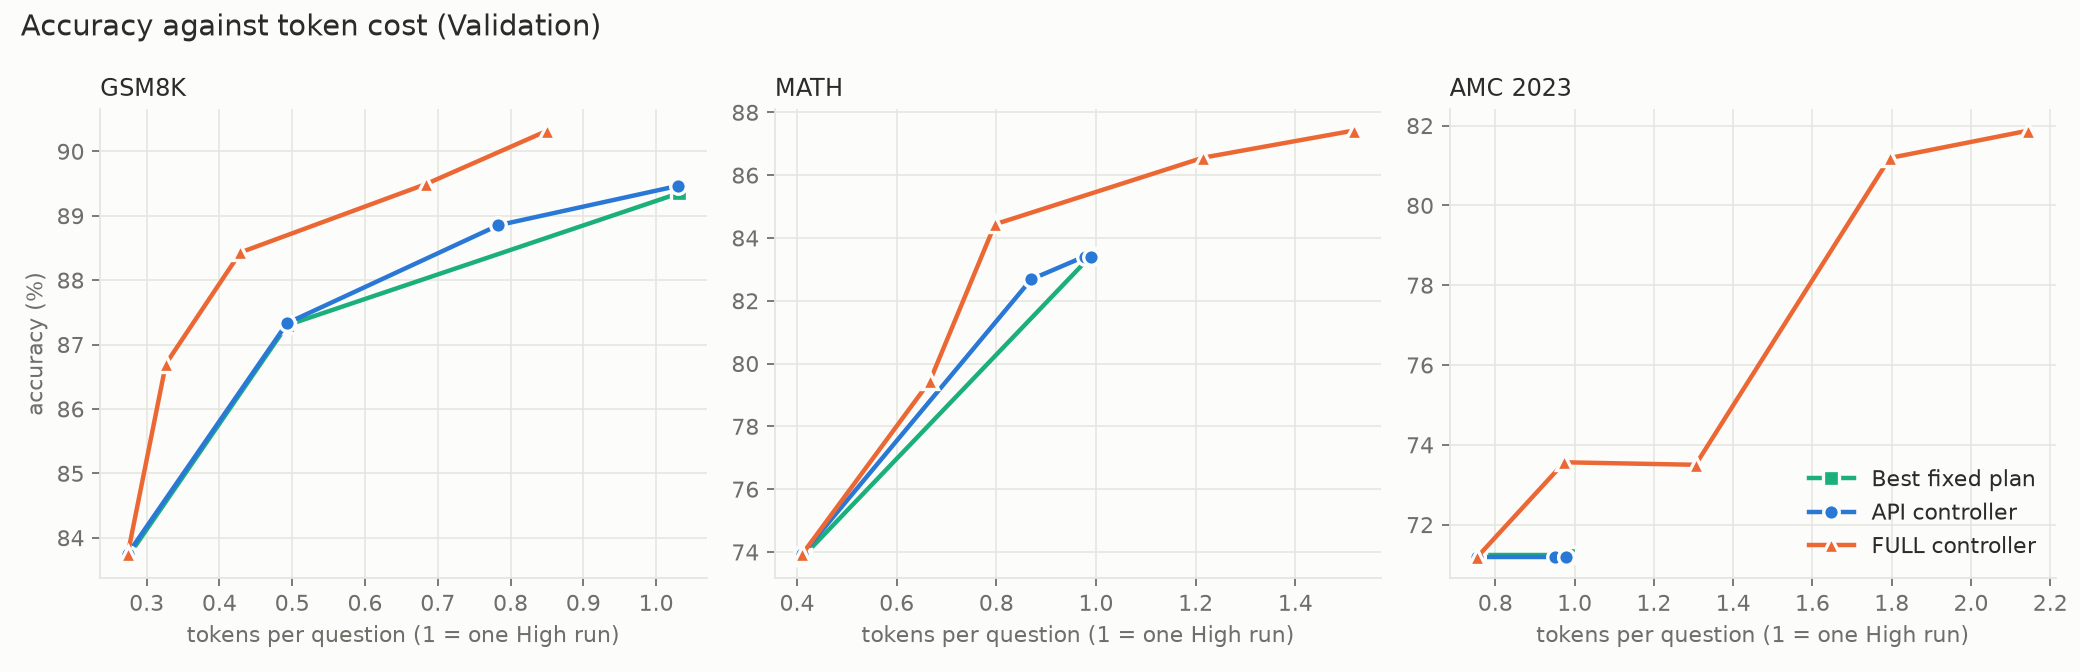

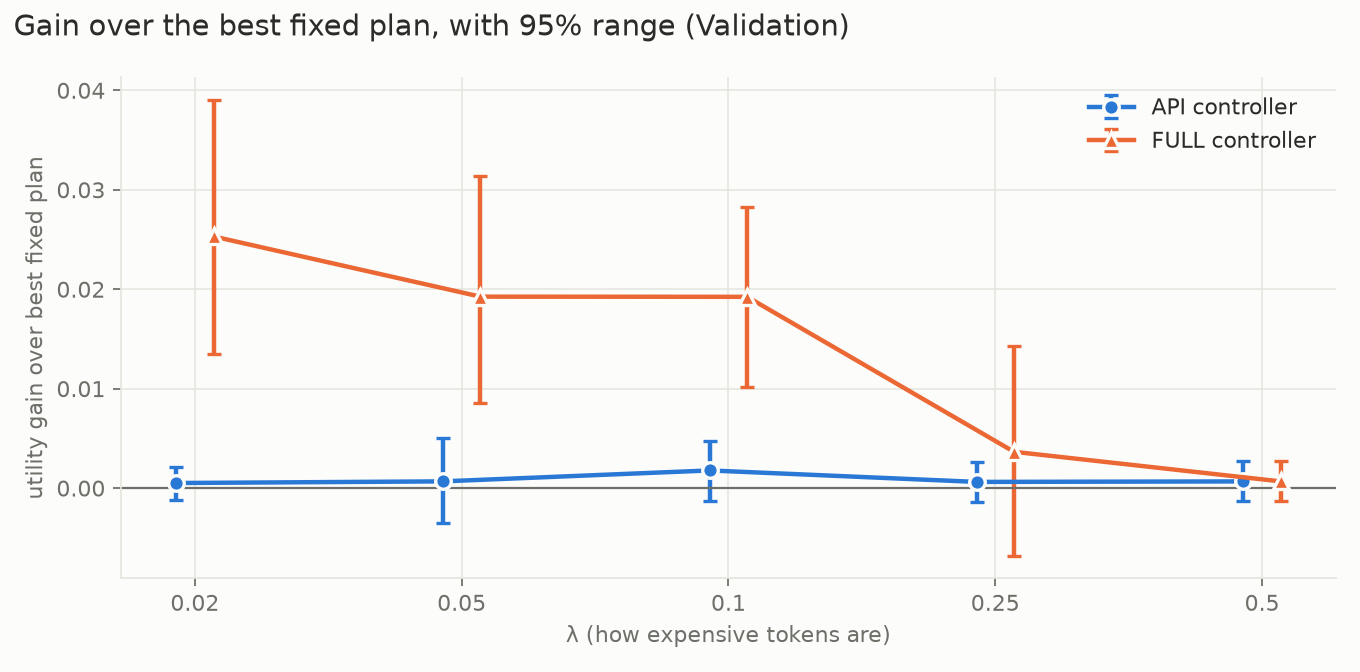

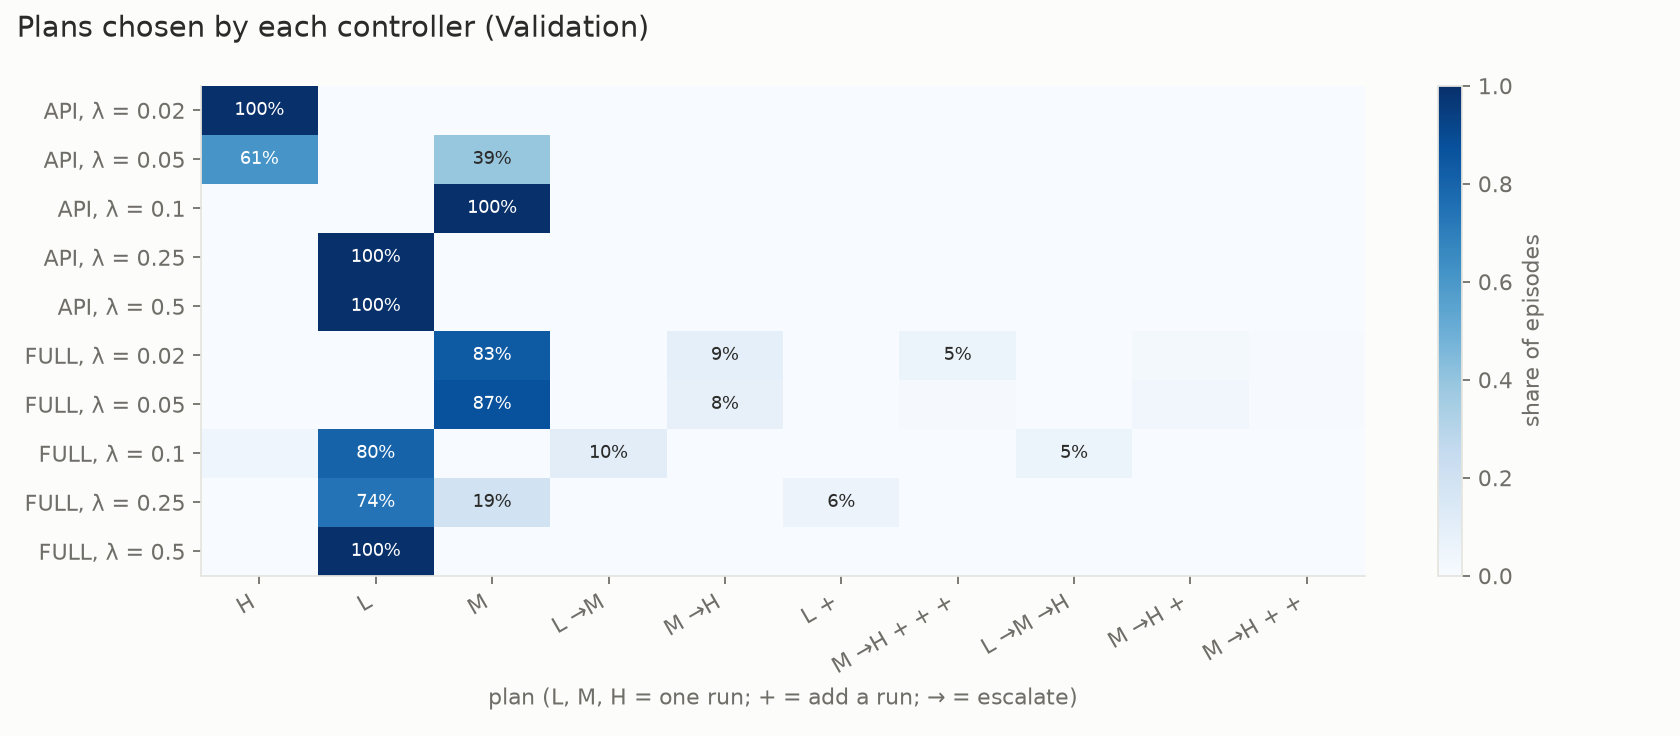

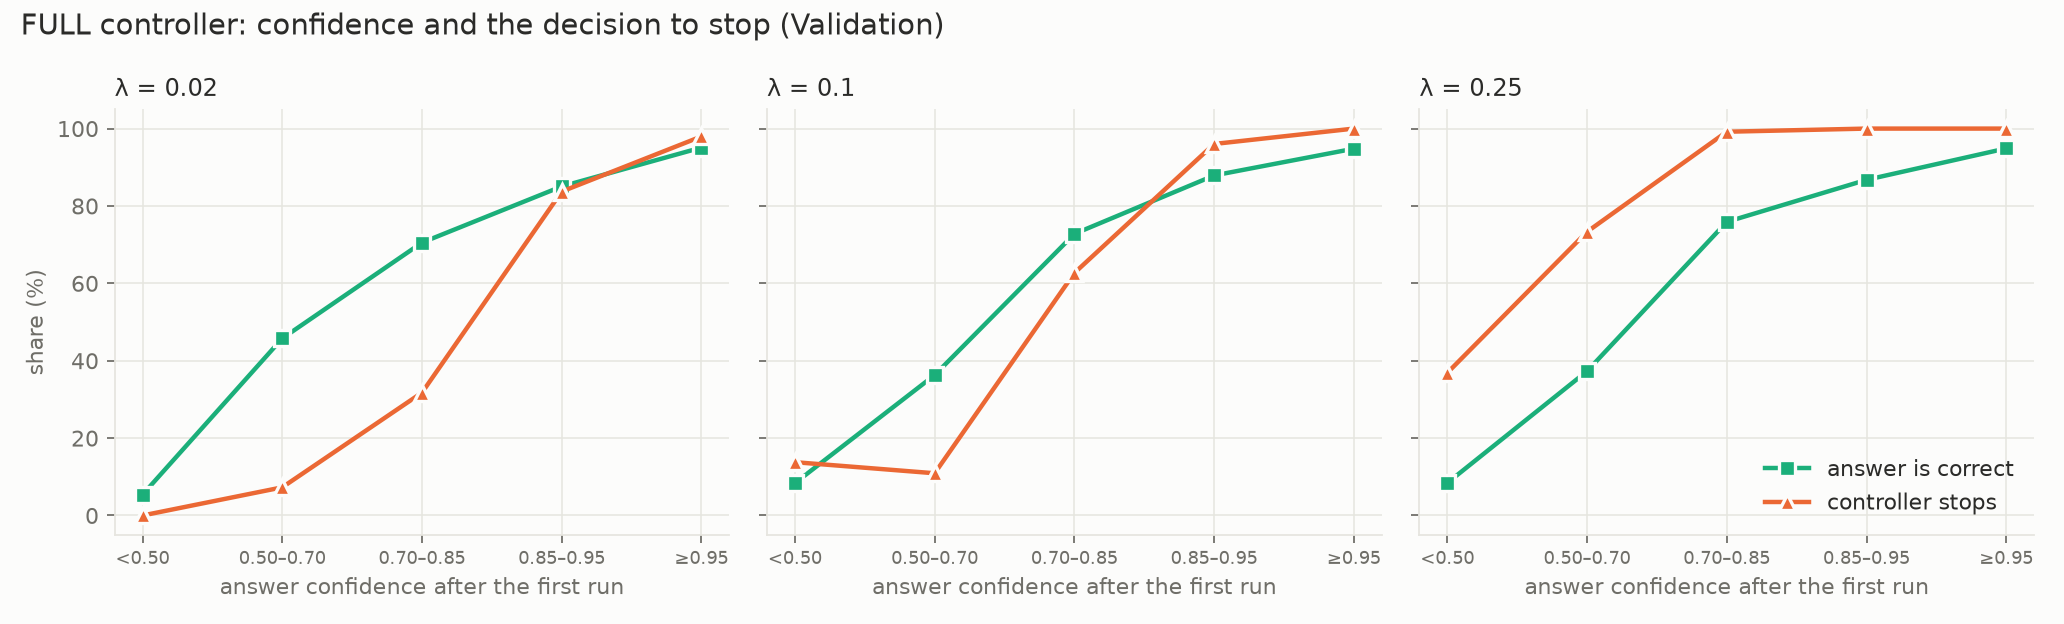

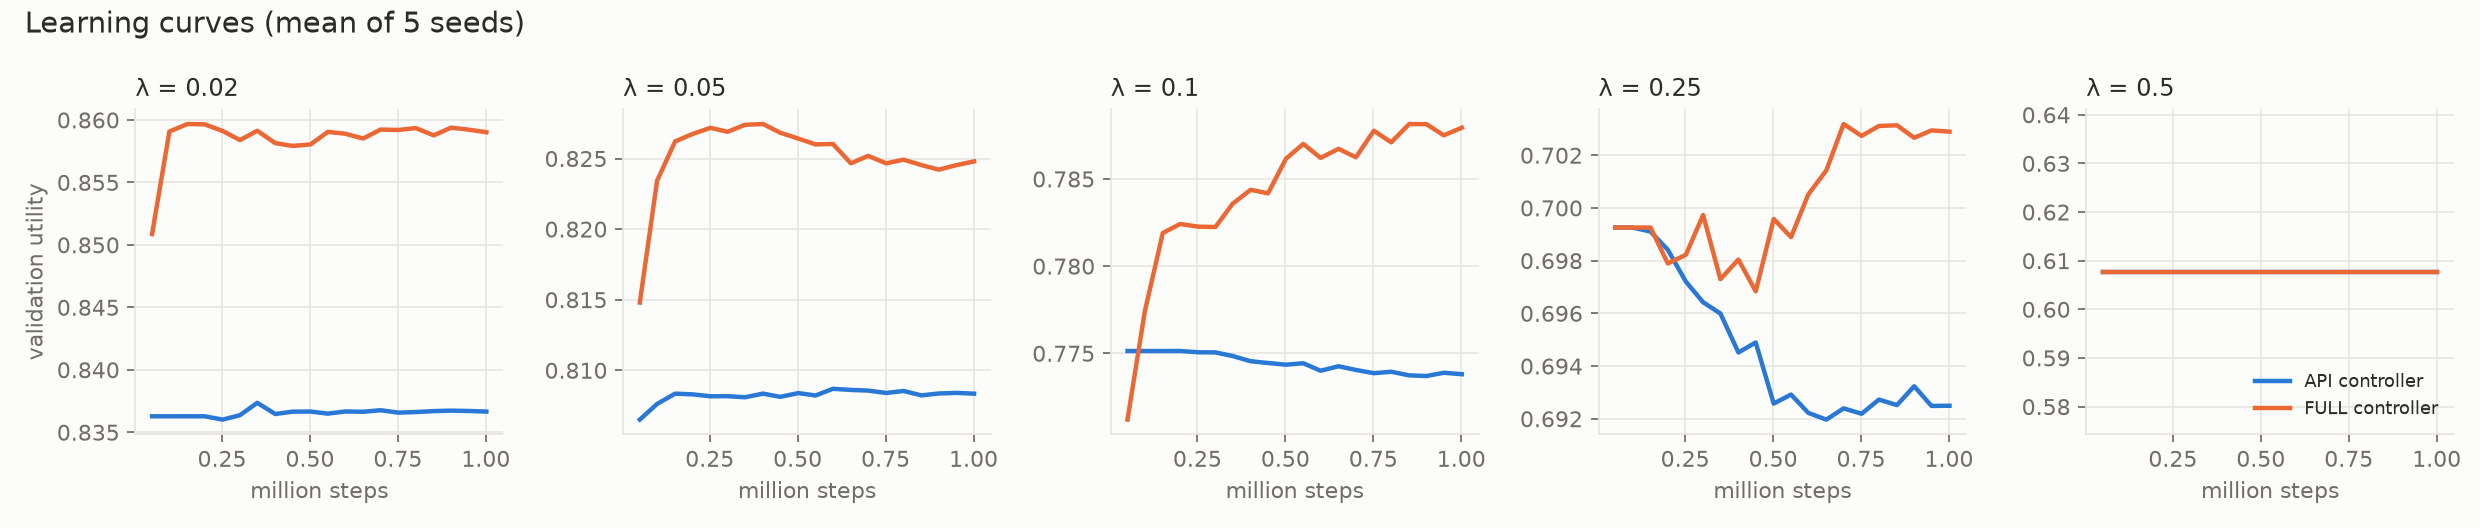

In [17]:
for path in sorted(FIGURES.glob(f"{split}_*.png")) + [FIGURES / "05_learning_curves.png"]:
    display(Image(filename=str(path), width=900))

## 16. All controllers together

In [18]:
bandit = pd.read_csv(ROOT / "rl_training/outputs/bandit" / f"{split}_results.csv")
bandit = bandit[bandit.dataset == "all (weighted)"].rename(columns={"λ": "lam"})
opened = pd.read_csv(ROOT / "rl_training/outputs/open_loop" / f"{split}_metrics.csv")
opened = opened[(opened.dataset == "weighted") & (opened.method == "OL-PPO")]
closed = metrics[metrics.dataset == "all (weighted)"]
table = pd.DataFrame({"Best fixed": closed[closed.model == BEST_FIXED].set_index("lam").utility,
                      "Bandit BD-1": bandit[bandit.method == "BD-1"].set_index("lam").utility,
                      "Bandit BD-2": bandit[bandit.method == "BD-2"].set_index("lam").utility,
                      "Open-loop PPO": opened.set_index("lam").utility,
                      "Closed-loop API": closed[closed.model == "API-PPO"].set_index("lam").utility,
                      "Closed-loop FULL": closed[closed.model == "FULL-PPO"].set_index("lam").utility,
                      "Oracle": closed[closed.model == ORACLE].set_index("lam").utility})
table.to_csv(OUT / f"{split}_all_controllers.csv")
display(table.round(4))

,Best fixed,Bandit BD-1,Bandit BD-2,Open-loop PPO,Closed-loop API,Closed-loop FULL,Oracle
lam,,,,,,,
0.02,0.8358,0.8348,0.8358,0.8358,0.8363,0.8611,0.8714
0.05,0.8089,0.8084,0.8092,0.8095,0.8096,0.8282,0.8435
0.10,0.7734,0.7756,0.7755,0.7755,0.7751,0.7926,0.8085
0.25,0.6986,0.6965,0.6986,0.6986,0.6993,0.7023,0.7278
0.50,0.6070,0.6070,0.6070,0.6070,0.6077,0.6077,0.6194


## 17. Test results

The saved models were evaluated once on the test split. This cell only reads the saved results.

All controllers: test utility


,Best fixed,Bandit BD-1,Bandit BD-2,Open-loop PPO,Closed-loop API,Closed-loop FULL,Oracle
lam,,,,,,,
0.02,0.8374,0.8352,0.8373,0.8374,0.8369,0.8679,0.8837
0.05,0.8140,0.8120,0.8131,0.8144,0.8114,0.8356,0.8560
0.10,0.7801,0.7804,0.7804,0.7804,0.7797,0.8029,0.8201
0.25,0.7150,0.7117,0.7150,0.7150,0.7146,0.7148,0.7400
0.50,0.6228,0.6228,0.6228,0.6228,0.6223,0.6223,0.6333


Test accuracy, all datasets


model,API-PPO,FULL-PPO,best fixed plan,"rule: M, escalate if cut",oracle
lam,,,,,
0.02,0.8562,0.8932,0.8567,0.8525,0.9047
0.05,0.8542,0.8840,0.8496,0.8525,0.8991
0.10,0.8462,0.8687,0.8507,0.8525,0.8841
0.25,0.8069,0.8380,0.8071,0.8525,0.8591
0.50,0.8069,0.8069,0.8071,0.8525,0.8356


Per dataset


accuracy                              tokens             \
model         API-PPO FULL-PPO best fixed plan    API-PPO   FULL-PPO   
dataset lam                                                            
amc23   0.02    0.660    0.814           0.663  16122.967  39366.406   
        0.05    0.660    0.784           0.663  16122.967  27346.377   
        0.10    0.673    0.714           0.675  15390.408  21349.199   
        0.25    0.614    0.634           0.613  10851.040  13205.915   
        0.50    0.614    0.614           0.613  10851.040  10851.040   
gsm8k   0.02    0.910    0.922           0.910   6397.896   4768.758   
        0.05    0.906    0.916           0.897   5028.609   3953.645   
        0.10    0.897    0.911           0.897   3195.501   2495.885   
        0.25    0.867    0.895           0.867   1828.564   2191.656   
        0.50    0.867    0.867           0.867   1828.564   1828.564   
math    0.02    0.823    0.870           0.824   8364.074  14833.902   
        0.05    0.823    0.860           0.824   8290.555  11239.270   
        0.10    0.812    0.842           0.824   7354.020   7560.895   
        0.25    0.763    0.802           0.764   3593.952   5492.054   
        0.50    0.763    0.763           0.764   3593.952   3593.952   

                              
model        best fixed plan  
dataset lam                   
amc23   0.02       16004.900  
        0.05       16004.900  
        0.10       15270.725  
        0.25       10782.588  
        0.50       10782.588  
gsm8k   0.02        6382.890  
        0.05        3190.745  
        0.10        3190.745  
        0.25        1827.248  
        0.50        1827.248  
math    0.02        8369.075  
        0.05        8369.075  
        0.10        8369.075  
        0.25        3596.581  
        0.50        3596.581

... (2 outputs left out)

Chosen policies


dataset                       all (weighted)                           amc23  \
model    lam                                                                   
API-PPO  0.02                         H 100%                          H 100%   
         0.05                   H 64%, M 36%                          H 100%   
         0.10                         M 100%                          M 100%   
         0.25                         L 100%                          L 100%   
         0.50                         L 100%                          L 100%   
FULL-PPO 0.02  M 83%, M →H 8%, M →H + + + 7%  M 57%, M →H + + + 32%, M →H 7%   
         0.05      M 87%, M →H 8%, M →H + 4%     M 61%, M →H + 16%, M →H 14%   
         0.10     L 81%, L →M 9%, L →M →H 7%    L 57%, L →M →H 26%, L →M 17%   
         0.25           L 71%, M 22%, L + 6%            M 50%, L 42%, L + 8%   
         0.50                         L 100%                          L 100%   

dataset                             gsm8k                            math  
model    lam                                                               
API-PPO  0.02                      H 100%                          H 100%  
         0.05                M 52%, H 48%                    H 79%, M 21%  
         0.10                      M 100%                          M 100%  
         0.25                      L 100%                          L 100%  
         0.50                      L 100%                          L 100%  
FULL-PPO 0.02   M 90%, M →H 7%, M →H + 2%  M 76%, M →H + + + 11%, M →H 9%  
         0.05   M 93%, M →H 6%, M →H + 1%       M 82%, M →H 9%, M →H + 6%  
         0.10  L 89%, L →M 9%, L →M →H 2%    L 74%, L →M →H 11%, L →M 10%  
         0.25        L 80%, M 14%, L + 5%            L 64%, M 28%, L + 7%  
         0.50                      L 100%                          L 100%

How confidence drives the first decision (FULL)


,model,lam,confidence,share_of_answers,answer_correct,controller_stops
5,FULL-PPO,0.02,<0.50,0.068,0.041,0.000
6,FULL-PPO,0.02,0.50–0.70,0.042,0.381,0.075
7,FULL-PPO,0.02,0.70–0.85,0.059,0.643,0.447
8,FULL-PPO,0.02,0.85–0.95,0.152,0.848,0.887
9,FULL-PPO,0.02,≥0.95,0.679,0.980,0.976
15,FULL-PPO,0.05,<0.50,0.068,0.041,0.004
16,FULL-PPO,0.05,0.50–0.70,0.042,0.381,0.127
17,FULL-PPO,0.05,0.70–0.85,0.059,0.643,0.628
18,FULL-PPO,0.05,0.85–0.95,0.152,0.848,0.968
19,FULL-PPO,0.05,≥0.95,0.679,0.980,0.999


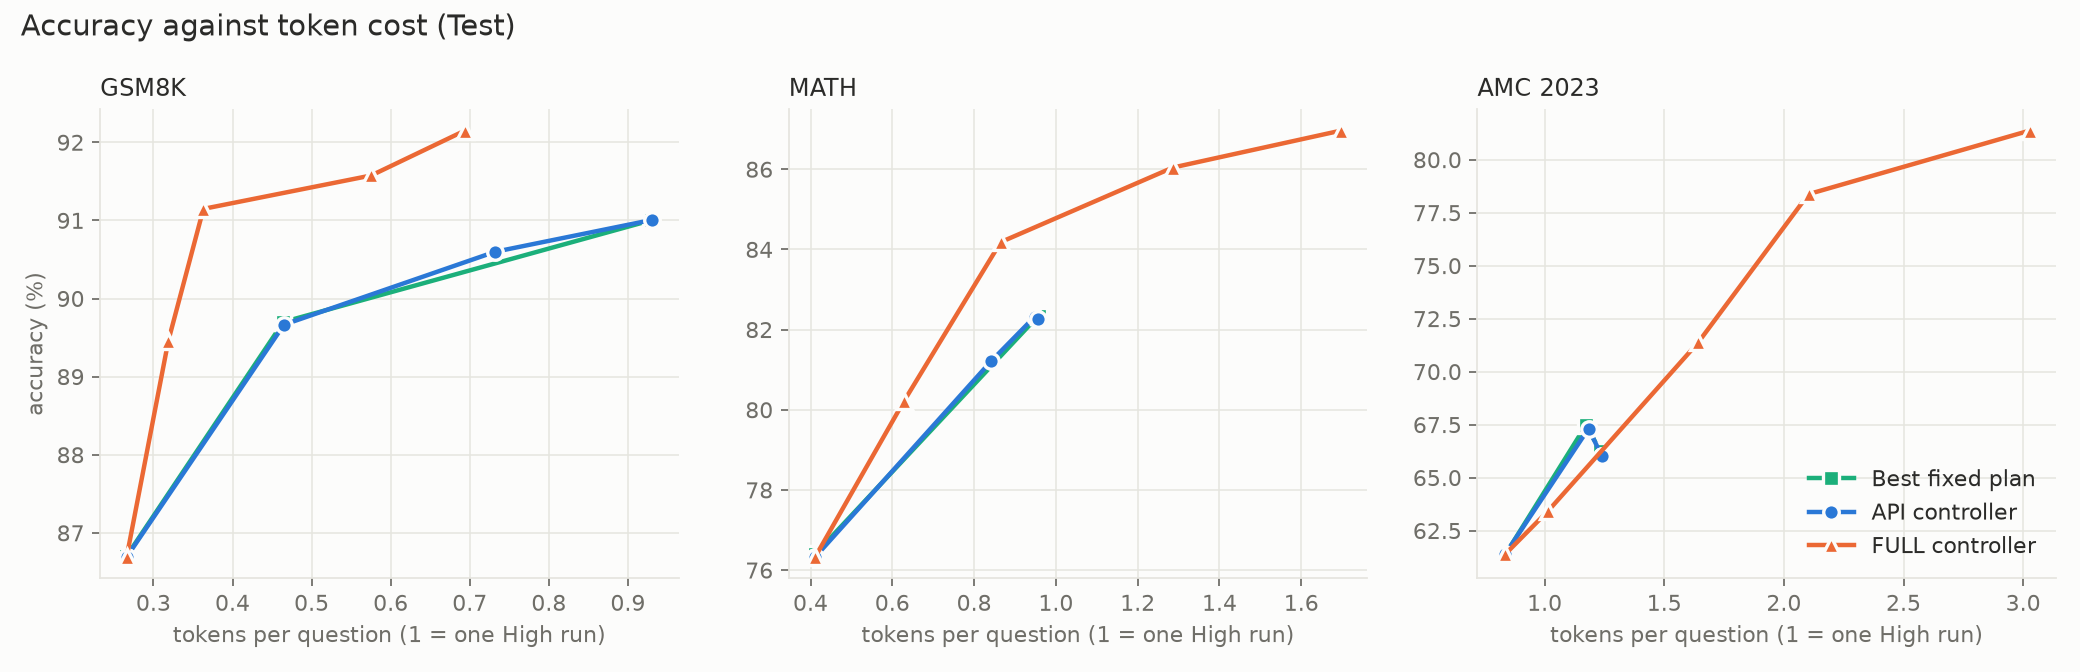

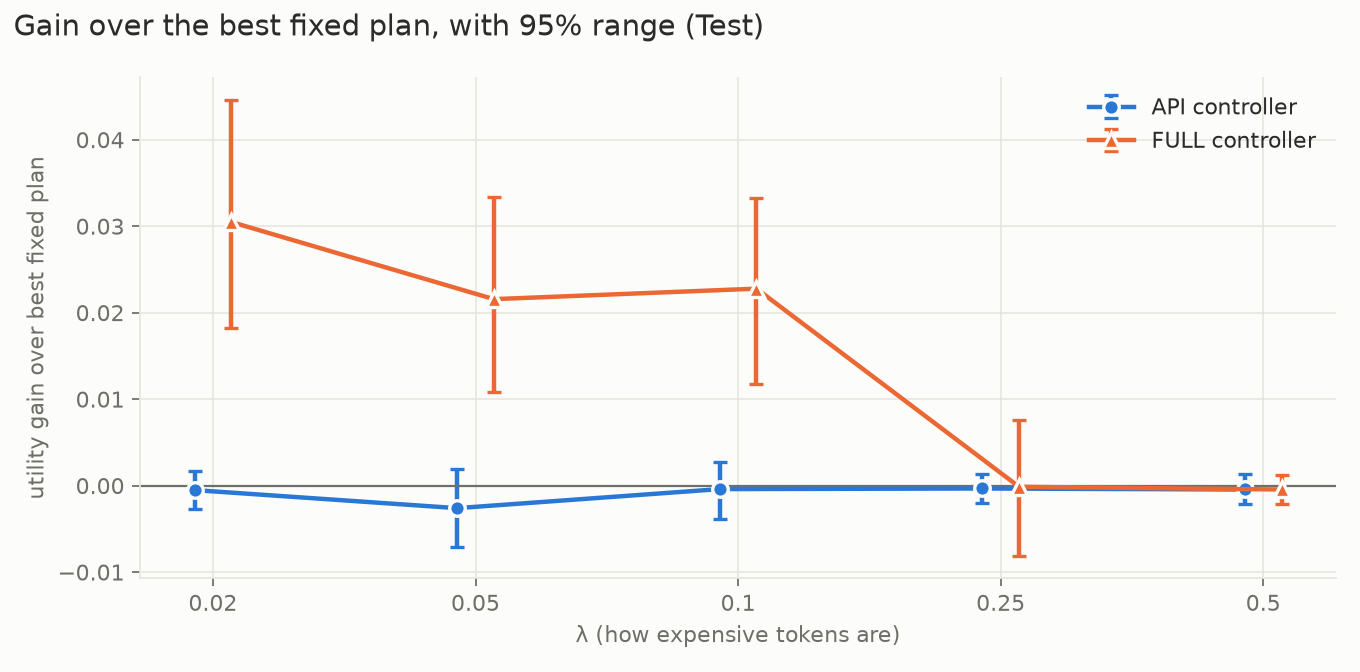

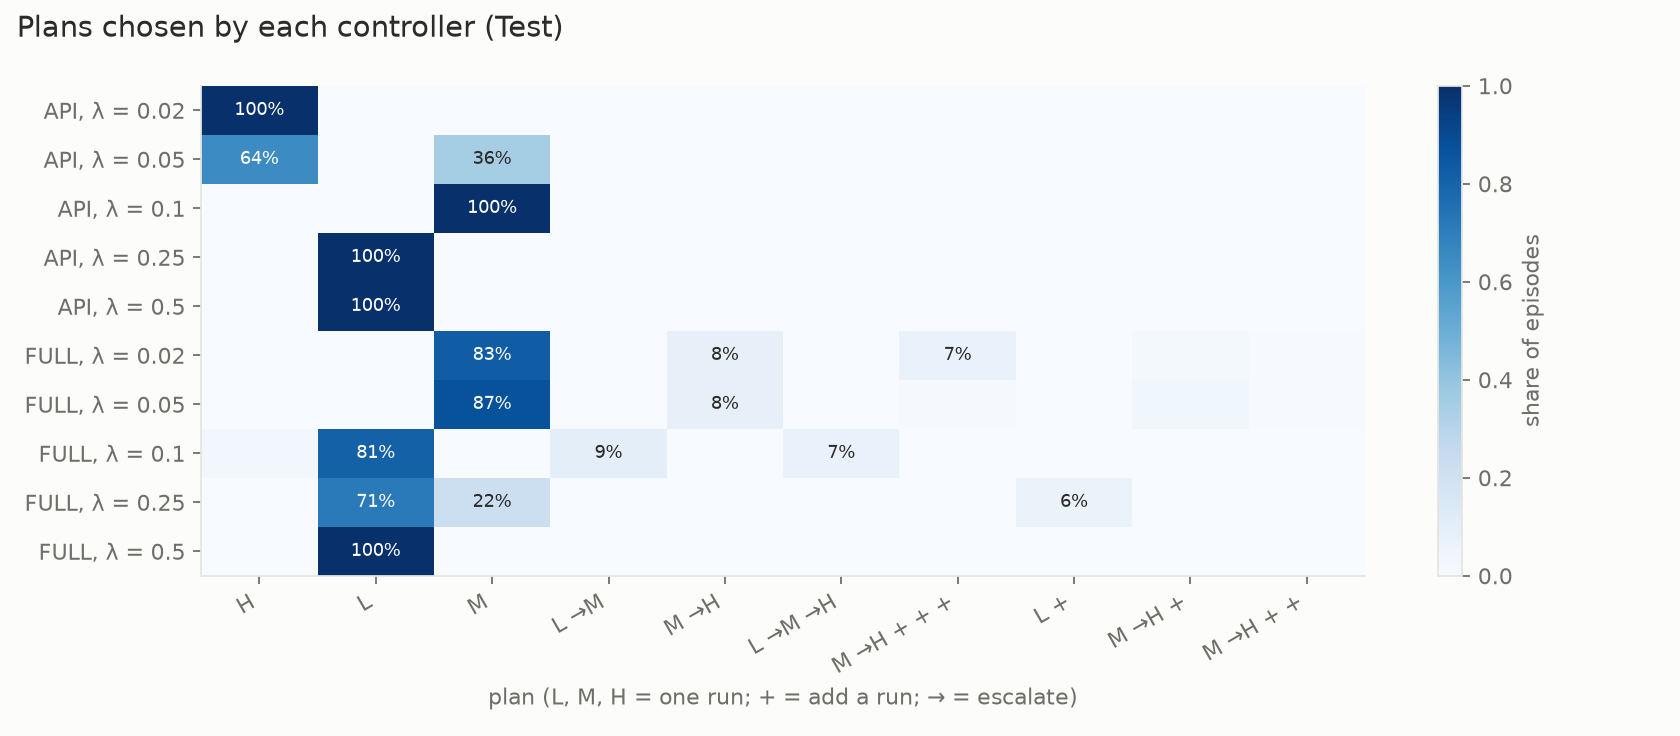

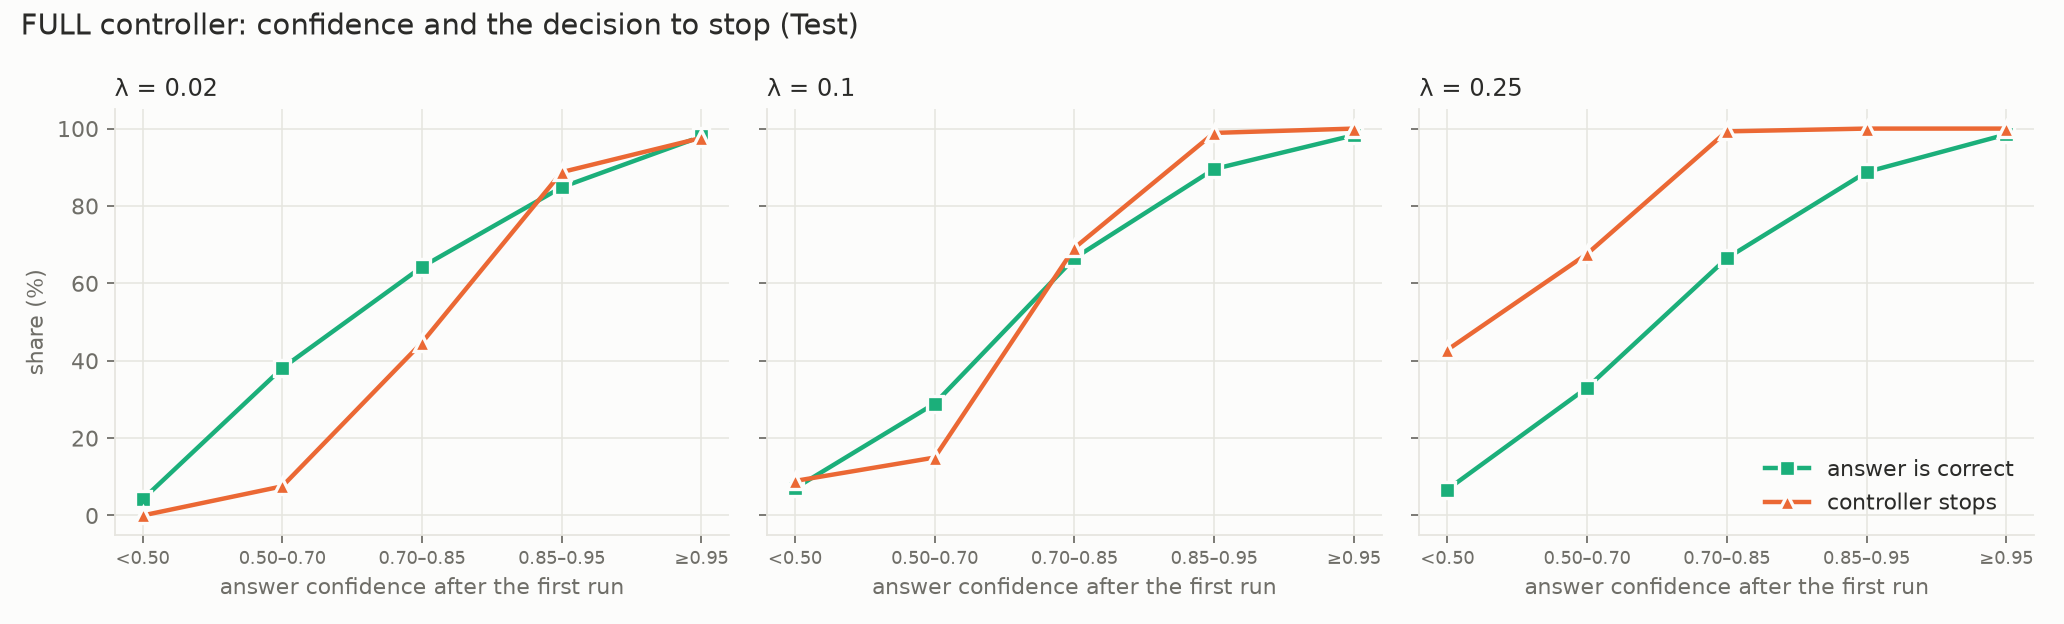

In [19]:
from IPython.display import Image, display
import pandas as pd
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "controller_data").is_dir())
OUT, FIG = ROOT / "rl_training/outputs/closed_loop", ROOT / "figures/closed_loop"
print("All controllers: test utility")
display(pd.read_csv(OUT / "test_all_controllers.csv", index_col=0).round(4))
results = pd.read_csv(OUT / "test_metrics.csv")
order = ["API-PPO", "FULL-PPO", "best fixed plan", "rule: M, escalate if cut", "oracle"]
print("Test accuracy, all datasets")
display(results[results.dataset == "all (weighted)"].pivot(index="lam", columns="model", values="accuracy")[order].round(4))
print("Per dataset")
display(results[(results.dataset != "all (weighted)") & results.model.isin(order[:3])].pivot(index=["dataset", "lam"], columns="model", values=["accuracy", "tokens"]).round(3))
print("Comparisons")
display(pd.read_csv(OUT / "test_comparisons.csv").round(4))
policies = pd.read_csv(OUT / "test_policies.csv")
top = (policies.sort_values("share", ascending=False).groupby(["model", "lam", "dataset"]).head(3)
       .assign(text=lambda x: x.plan + " " + (100 * x.share).round().astype(int).astype(str) + "%")
       .groupby(["model", "lam", "dataset"]).text.agg(", ".join).unstack())
print("Chosen policies")
display(top)
print("How confidence drives the first decision (FULL)")
confidence = pd.read_csv(OUT / "test_confidence.csv")
display(confidence[confidence.model == "FULL-PPO"].round(3))
for path in sorted(FIG.glob("test_*.png")):
    display(Image(filename=str(path), width=900))
